# Predictors of Academic Performance
### A multivariate regression analysis of student exam scores

### Research question

1. Which factors have the strongest impact on academic performance (`Exam_Score`)?
2. How accurately can exam scores be predicted from these factors?

### Variables description

- **Hours_Studied**: Daily study hours
- **Attendance**: Class attendance percentage
- **Parental_Involvement**: Parents’ academic support (Low, Medium, High)
- **Access_to_Resources**: Learning resource availability (Low, Medium, High)
- **Extracurricular_Activities**: Participation in extracurricular activities (Yes/No)
- **Sleep_Hours**: Average sleep duration
- **Previous_Scores**: Past academic performance
- **Motivation_Level**: Student motivation level
- **Internet_Access**: Internet availability status
- **Tutoring_Sessions**: Extra tutoring frequency
- **Family_Income**: Proxy for socioeconomic status (Low, Medium, High)
- **Teacher_Quality**: Perceived teaching quality (Low, Medium, High)
- **School_Type**: Institutional difference (Public, Private)
- **Peer_Influence**: Influence of schoolmates on student (Positive, Negative, Neutral)
- **Physical_Activity**: Level of physical activity (0-6)
- **Learning_Disabilities** (Yes/No)
- **Parental_Education_Level**: Human capital background of the family (High school, College, Postgrad)
- **Distance_from_Home**: Distance between home and school (Near, Moderate, Far)
- **Gender**
- **Exam_Score**

### Data cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import statsmodels.api as sm 
import statsmodels.formula.api as smf

df = pd.read_csv("StudentPerformanceFactors.csv")
df.head(5)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
# Understanding the dataset dimension (n. rows and columns)
df.shape

(6607, 20)

In [3]:
# Null values detection
missing_values = df.isnull().sum()
print(df.isnull().sum())
print()
print(f'Total n of missing values: {missing_values.sum()}')
print(f'Percentage of missing values: {((missing_values.sum()/df.shape[0])*100).round(2)}%')
print(f'N of rows with at least 1 missing value: {df.isna().any(axis=1).sum()}')


Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

Total n of missing values: 235
Percentage of missing values: 3.56%
N of rows with at least 1 missing value: 229


Given that the number of missing values is distributed in the dataset and that it accounts for a small percentage of total observations, we can proceed dropping all rows with at least 1 missing value. 

In [4]:
# Dropping null rows
df.dropna(inplace=True)
# Domain validation: Exam_Score must lie within the 0-100 scale
out_of_range = df[~df['Exam_Score'].between(0, 100)]
print(f'Records outside the valid scale: {len(out_of_range)}')

df = df[df['Exam_Score'].between(0, 100)]
df.shape

Records outside the valid scale: 1


(6377, 20)

In [5]:
# Duplicates rows detection
df.duplicated().sum()    

np.int64(0)

### EDA and descriptive analysis

In [6]:
# Visualising descriptive statistics 
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6377.0,19.976008,5.985283,1.0,16.0,20.0,24.0,44.0
Attendance,6377.0,80.018034,11.549434,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6377.0,7.035126,1.468091,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6377.0,75.063353,14.399766,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6377.0,1.494747,1.233300,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6377.0,2.972714,1.029006,0.0,2.0,3.0,4.0,6.0
Exam_Score,6377.0,67.246825,3.891637,55.0,65.0,67.0,69.0,100.0


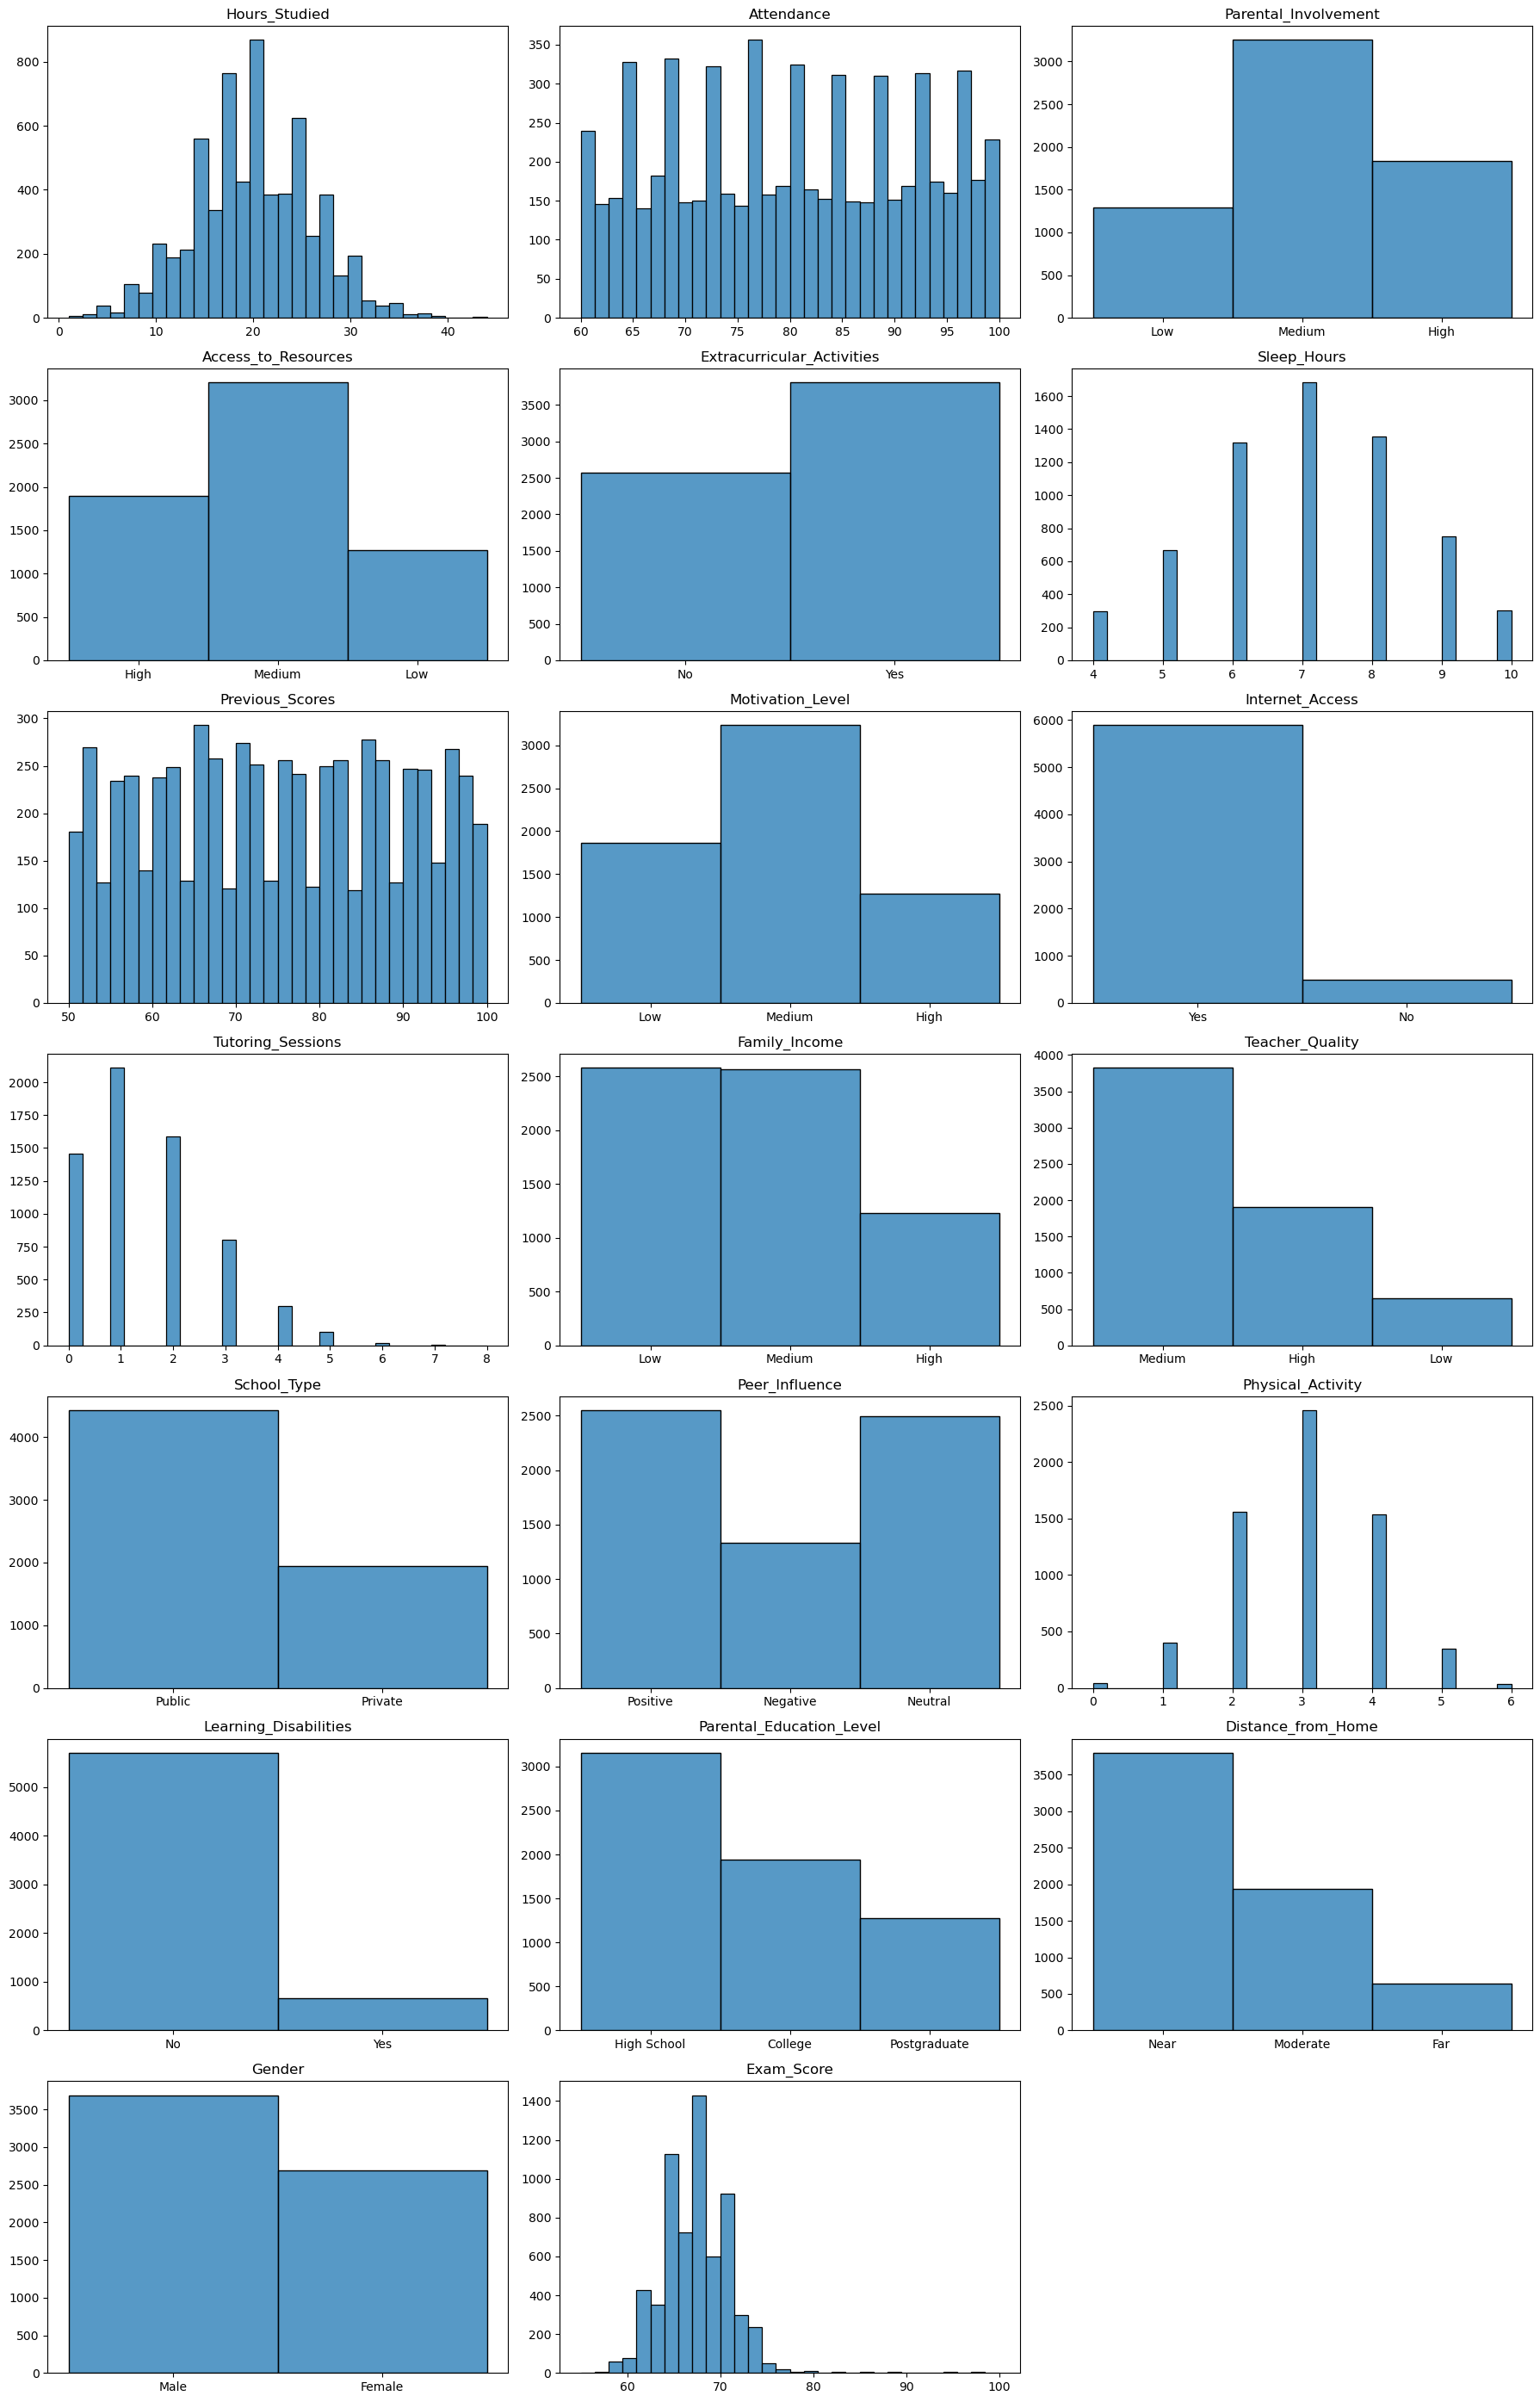

In [7]:
# Plotting variables distributions
cols = df.columns

n_cols = 3
n_rows = math.ceil(len(cols) / n_cols)

plt.figure(figsize=(18, 4 * n_rows))

for i, col in enumerate(cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(df[col], bins=30)
    plt.title(col)
    plt.xlabel("")
    plt.ylabel("")

plt.tight_layout()
plt.show()

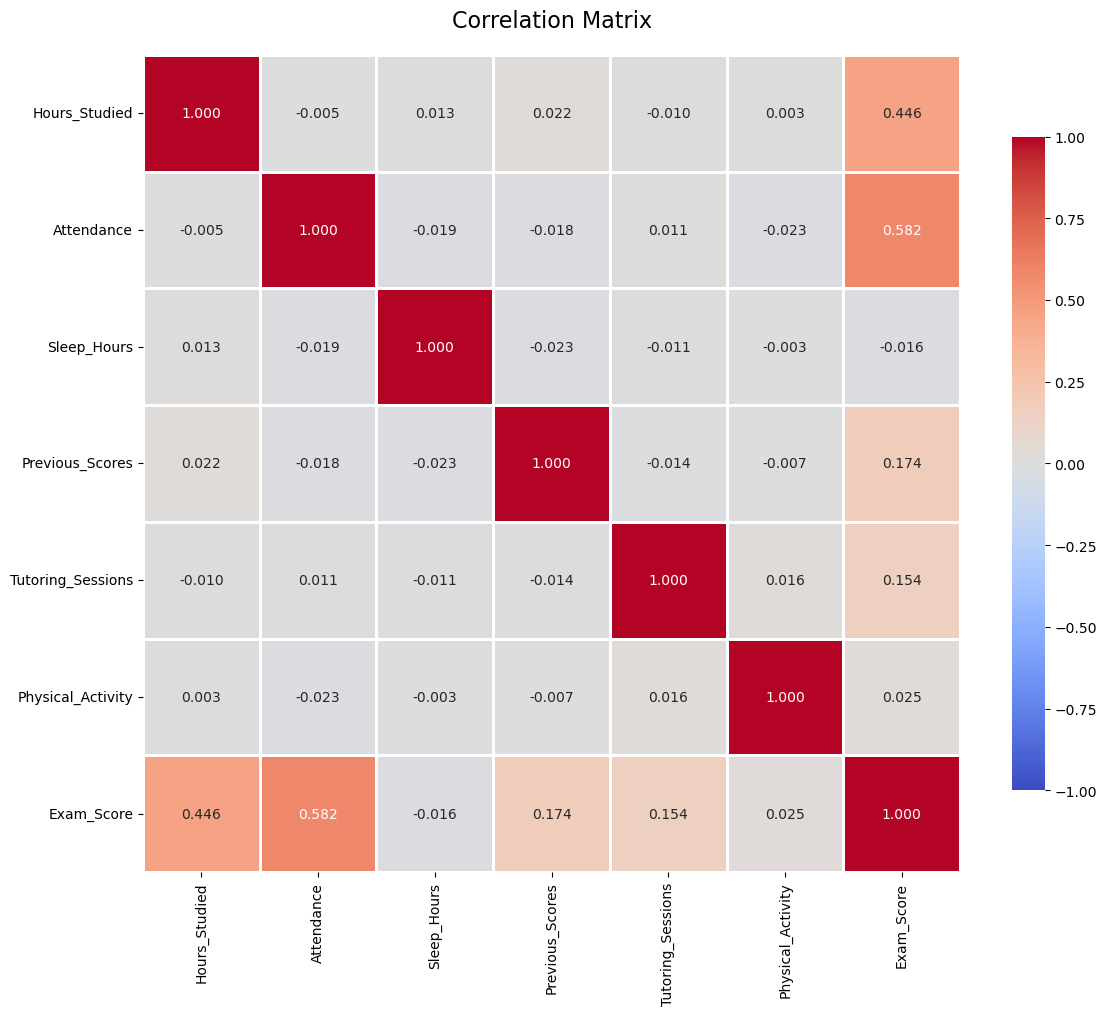

In [8]:
# Visualizing correlation matrix 

corr_matrix = df.select_dtypes(include=["int64", "float64"]).corr()
plt.figure(figsize=(12, 10))

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, vmin=-1, vmax=1)
plt.title('Correlation Matrix', fontsize=16, pad=20) 
plt.tight_layout() 
plt.show()

In [9]:
# Visualize features with higher correlation with Exam_score
corr_matrix['Exam_Score'].sort_values(ascending=False)[1:]

Attendance           0.581664
Hours_Studied        0.446174
Previous_Scores      0.173635
Tutoring_Sessions    0.153986
Physical_Activity    0.025260
Sleep_Hours         -0.016314
Name: Exam_Score, dtype: float64

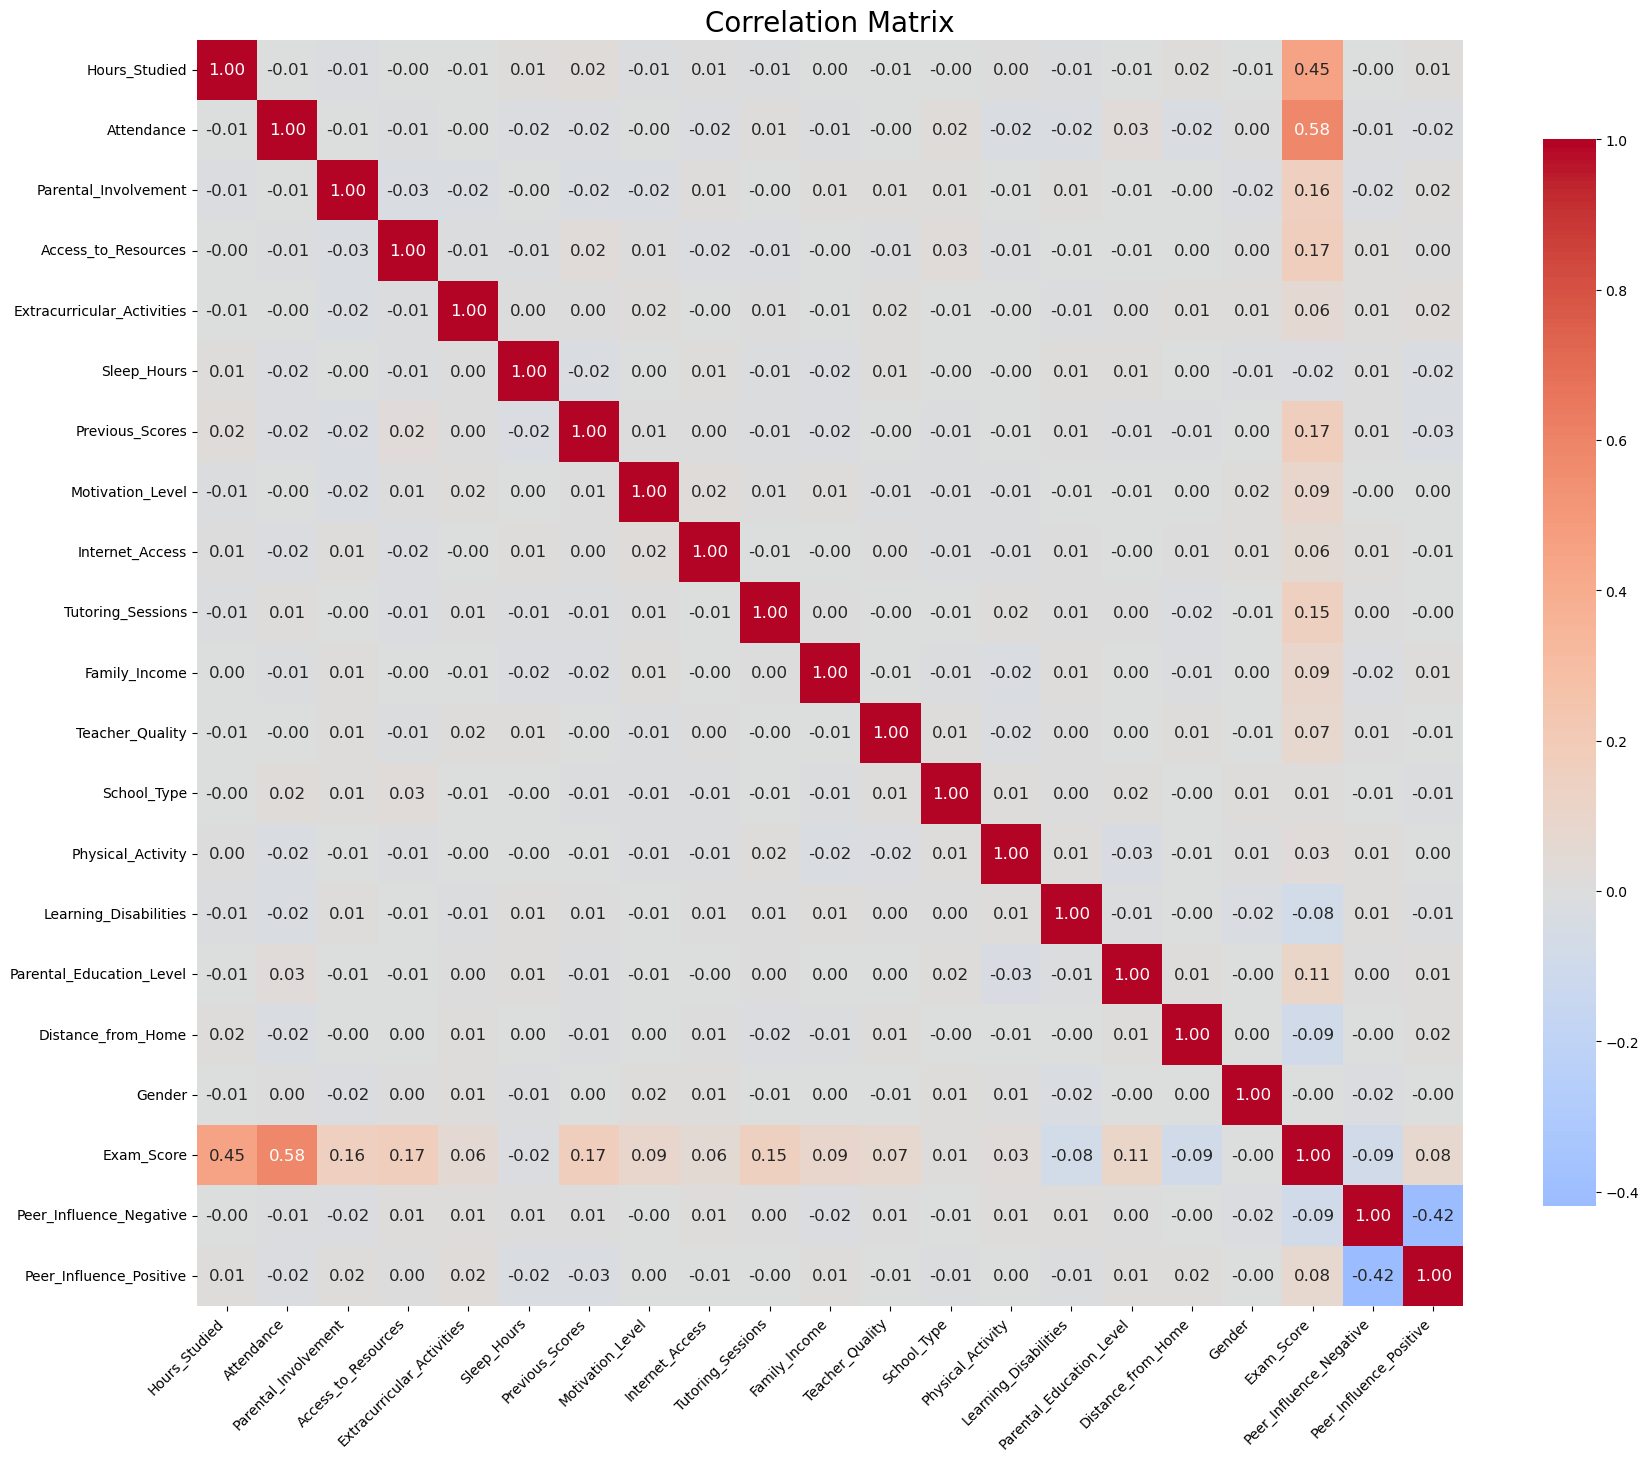

In [10]:
# Transforming categorical into numerical features: encoding

# Create a copy of dataset
df_enc = df.copy()

# Mappings (ordinal / binary encoding)
maps = {
    "Parental_Involvement": {"Low": 1, "Medium": 2, "High": 3},
    "Access_to_Resources": {"Low": 1, "Medium": 2, "High": 3},
    "Motivation_Level": {"Low": 1, "Medium": 2, "High": 3},
    "Family_Income": {"Low": 1, "Medium": 2, "High": 3},
    "Teacher_Quality": {"Low": 1, "Medium": 2, "High": 3},
    "Parental_Education_Level": {"High School": 1, "College": 2, "Postgraduate": 3},
    "Distance_from_Home": {"Near": 1, "Moderate": 2, "Far": 3},
    "Extracurricular_Activities": {"No": 0, "Yes": 1},
    "Internet_Access": {"No": 0, "Yes": 1},
    "Learning_Disabilities": {"No": 0, "Yes": 1},
    "Gender": {"Female": 0, "Male": 1},
    "School_Type": {"Public": 0, "Private": 1},
}

# Standardize string columns (avoids NaN introduced by .map due to stray spaces / formatting)
for col in list(maps.keys()) + ["Peer_Influence"]:
    if df_enc[col].dtype == "object":
        df_enc[col] = df_enc[col].str.strip()

# Apply mappings
for col, m in maps.items():
    df_enc[col] = df_enc[col].map(m)

# Create dummy variables for Peer_Influence
peer_dummies = pd.get_dummies(
    df_enc["Peer_Influence"],
    prefix="Peer_Influence",
    drop_first=False
)

# Keep Neutral as reference category -> drop it
peer_dummies = peer_dummies.drop(columns=["Peer_Influence_Neutral"], errors="ignore")

# Merge dummies and drop original column
df_enc = pd.concat([df_enc.drop(columns=["Peer_Influence"]), peer_dummies], axis=1)

# Drop rows with NaN values created by unmapped categories
required_cols = list(maps.keys()) + ["Exam_Score"]
df_enc = df_enc.dropna(subset=required_cols).reset_index(drop=True)

# Convert dummy columns to integers
for col in peer_dummies.columns:
    df_enc[col] = df_enc[col].astype(int)

# Visualize complete correlation matrix
corr = df_enc.corr(numeric_only=True)

plt.figure(figsize=(18, 15))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    annot_kws={"size": 12},
    cbar_kws={"shrink": 0.8},
)

plt.title("Correlation Matrix", fontsize=20)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()


### Multivariate regression (OLS)

In [11]:
# Building model pipeline

## Train/Test split
from sklearn.model_selection import train_test_split
import statsmodels.formula.api as smf

X = df_enc.drop(columns=["Exam_Score"])
y = df_enc["Exam_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Verify split was successful 
print(X_train.shape)
print(X_test.shape)

## Create train and test dataframes to estimate and then apply the model
df_train = X_train.copy()
df_train['Exam_Score'] = y_train

df_test = X_test.copy()
df_test['Exam_Score'] = y_test

## Estimating the model on train set
reg_model = smf.ols(
    '''Exam_Score ~ Attendance + Hours_Studied + Previous_Scores
    + Tutoring_Sessions + Physical_Activity
    + Parental_Involvement + Access_to_Resources
    + Extracurricular_Activities + Motivation_Level
    + Internet_Access + Family_Income
    + Teacher_Quality + Peer_Influence_Positive
    + Peer_Influence_Negative + Learning_Disabilities
    + Parental_Education_Level
    + Distance_from_Home + Gender
    + School_Type + Sleep_Hours''',
    data=df_train
).fit()

## Predicting using test set
y_pred_train = reg_model.predict(X_train)
y_pred_test = reg_model.predict(X_test)


(5101, 20)
(1276, 20)


In [12]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Model evaluation (Train vs Test): MAE, MSE and RMSE

## Evaluating in-sample performance
print(reg_model.summary())

# TRAIN
mae_train  = round(mean_absolute_error(y_train, y_pred_train), 2)
mse_train  = round(mean_squared_error(y_train, y_pred_train), 2)
rmse_train = round(np.sqrt(mean_squared_error(y_train, y_pred_train)), 2)

# TEST
mae_test  = round(mean_absolute_error(y_test, y_pred_test), 2)
mse_test  = round(mean_squared_error(y_test, y_pred_test), 2)
rmse_test = round(np.sqrt(mean_squared_error(y_test, y_pred_test)), 2)

print()
print("TRAIN PERFORMANCE")
print("MAE:", mae_train)
print("MSE:", mse_train)
print("RMSE:", rmse_train)

print("\nTEST PERFORMANCE")
print("MAE:", mae_test)
print("MSE:", mse_test)
print("RMSE:", rmse_test)

                            OLS Regression Results                            
Dep. Variable:             Exam_Score   R-squared:                       0.723
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     662.4
Date:                Sat, 05 Sep 2026   Prob (F-statistic):               0.00
Time:                        12:50:48   Log-Likelihood:                -10875.
No. Observations:                5101   AIC:                         2.179e+04
Df Residuals:                    5080   BIC:                         2.193e+04
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [13]:
# Model evaluation (Train vs Test): R² and Adjusted R²

from sklearn.metrics import r2_score

# -------------------------
# Train
# -------------------------
r2_train = reg_model.rsquared
adj_r2_train = reg_model.rsquared_adj

# -------------------------
# Test
# -------------------------
r2_test = r2_score(y_test, y_pred_test)

n_test = len(y_test)
k = X_test.shape[1]

adj_r2_test = 1 - (1 - r2_test) * (n_test - 1) / (n_test - k - 1)

# -------------------------
# Print comparison
# -------------------------
print()
print("R² comparison")
print(f"Train R²:      {r2_train:.3f}")
print(f"Test R²:       {r2_test:.3f}")

print("\nAdjusted R² comparison")
print(f"Train Adj R²:  {adj_r2_train:.3f}")
print(f"Test Adj R²:   {adj_r2_test:.3f}")



R² comparison
Train R²:      0.723
Test R²:       0.735

Adjusted R² comparison
Train Adj R²:  0.722
Test Adj R²:   0.731


                            OLS Regression Results                            
Dep. Variable:             Exam_Score   R-squared:                       0.723
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     662.4
Date:                Sat, 05 Sep 2026   Prob (F-statistic):               0.00
Time:                        12:50:48   Log-Likelihood:                -3965.3
No. Observations:                5101   AIC:                             7973.
Df Residuals:                    5080   BIC:                             8110.
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

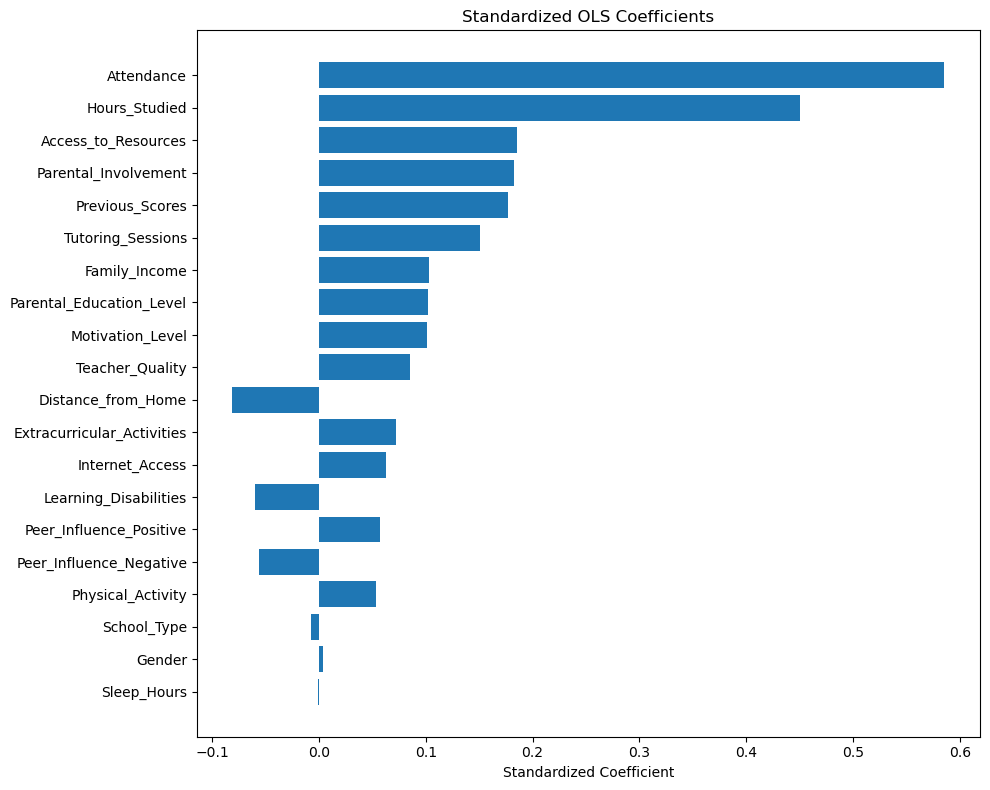

In [14]:
# Imports
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# -----------------------------
# 1. Standardize X and y on TRAIN set
# -----------------------------
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_std = pd.DataFrame(
    scaler_X.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_std = pd.DataFrame(
    scaler_X.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

y_train_std = pd.Series(
    scaler_y.fit_transform(y_train.to_frame()).flatten(),
    name="Exam_Score",
    index=y_train.index
)

y_test_std = pd.Series(
    scaler_y.transform(y_test.to_frame()).flatten(),
    name="Exam_Score",
    index=y_test.index
)

# -----------------------------
# 2. Add constant
# -----------------------------
X_train_std_const = sm.add_constant(X_train_std)
X_test_std_const = sm.add_constant(X_test_std)

# -----------------------------
# 3. Fit standardized OLS
# -----------------------------
std_model = sm.OLS(y_train_std, X_train_std_const).fit()

# Full summary
print(std_model.summary())

# -----------------------------
# 4. Table of standardized coefficients
# -----------------------------
std_coefs = pd.DataFrame({
    "Variable": std_model.params.index,
    "Std_Coefficient": std_model.params.values,
    "p_value": std_model.pvalues.values
})

# Drop intercept for comparison
std_coefs = std_coefs[std_coefs["Variable"] != "const"]

# Sort by absolute magnitude
std_coefs["Abs_Std_Coefficient"] = std_coefs["Std_Coefficient"].abs()
std_coefs = std_coefs.sort_values("Abs_Std_Coefficient", ascending=False)

print("\nStandardized coefficients ranked by absolute magnitude:")
print(std_coefs)

# -----------------------------
# 5. Optional: predictions on standardized test set
# -----------------------------
y_pred_test_std = std_model.predict(X_test_std_const)

# -----------------------------
# 6. Optional: simple bar plot of standardized coefficients
# -----------------------------
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.barh(std_coefs["Variable"], std_coefs["Std_Coefficient"])
plt.gca().invert_yaxis()
plt.xlabel("Standardized Coefficient")
plt.title("Standardized OLS Coefficients")
plt.tight_layout()
plt.show()

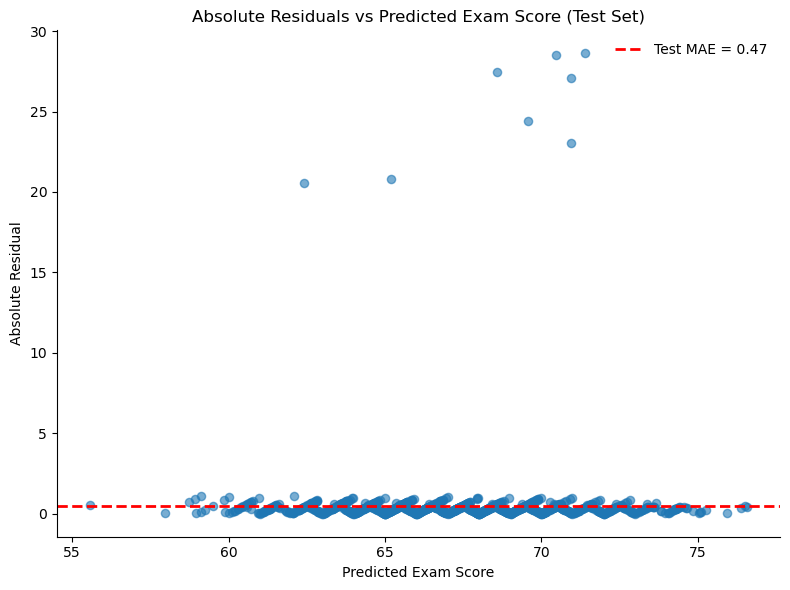

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

abs_residuals_test = np.abs(y_test - y_pred_test)

residuals_df = pd.DataFrame({
    "y_test": y_test,
    "y_pred_test": y_pred_test,
    "abs_residual": abs_residuals_test
})

mae_test = abs_residuals_test.mean()

plt.figure(figsize=(8, 6))
plt.scatter(
    residuals_df["y_pred_test"],
    residuals_df["abs_residual"],
    alpha=0.6,
    s=35
)

plt.axhline(
    y=mae_test,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Test MAE = {mae_test:.2f}"
)

plt.xlabel("Predicted Exam Score")
plt.ylabel("Absolute Residual")
plt.title("Absolute Residuals vs Predicted Exam Score (Test Set)")
plt.legend(frameon=False)
plt.grid(False)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

#### Comments

To perform our model evaluation we considered the following measures: 
$$
MAE = \frac{1}{n}\sum_{i=1}^{n} \left| y_i - \hat{y}_i \right|
$$

$$
MSE = \frac{1}{n}\sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2
$$

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2}
$$

All these measures capacity are lower in the test set, than in the train. 
This indicates that the model does not suffer from overfitting, but instead it learned from train set, generalizing well on the test set. 

Looking at the p-values for each coefficient it appears three of the regressors are not statistically significant: 
- Sleep_Hours (p-value = 0.880)
- School_Type (p-value = 0.322)
- Gender (p-value = 0.626).

To improve the model next steps are:
- excluding non-significant regressors
- looking for non-linear relationships between regressors and the dependent variable
- introduce interaction terms, if needed.